# setup + imports - din baseline mostly

In [40]:
from sklearn.decomposition import PCA
from matplotlib import pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import adjusted_rand_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [13]:
import librosa
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [26]:
TRAIN_PATH = "train_data.npz"
SAMPLE_RATE = 16000
N_MFCC = 20

data = np.load(TRAIN_PATH)

def extract_features(audio):
    mfcc = librosa.feature.mfcc(y=audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

train_features = np.stack([extract_features(audio) for audio in data["audio"]])

X = train_features

scaler = StandardScaler().fit(train_features)
train_features = scaler.transform(train_features)

speakers = data['speaker_id']


In [27]:
TEST_PATH = "test_data.npz"

test_data = np.load(TEST_PATH)

test_features = np.stack([extract_features(audio) for audio in test_data["audio"]])
test_features = scaler.transform(test_features)


# data exploration

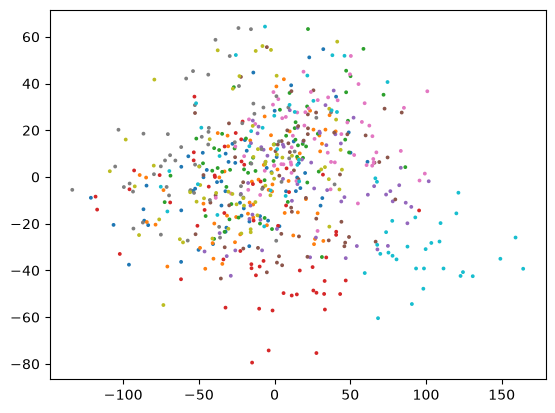

In [28]:
P = PCA(n_components=2).fit_transform(X)
plt.scatter(P[:, 0], P[:, 1], s=3, c=data['speaker_id'], cmap='tab10'); plt.show()

# validation

In [46]:
def evalcl(method, X, speakers):
    kf = GroupKFold(n_splits=2)
    scores = []
    for fit_rows, val_rows in kf.split(X, groups=speakers):
        X_fit = X[fit_rows]
        y_fit = speakers[fit_rows]
        X_val = X[val_rows]
        y_val = speakers[val_rows]

        k = len(np.unique(y_val))
        preds = method(X_fit, y_fit, X_val, k)
        scores.append(adjusted_rand_score(preds, y_val))
    print('folds:', [round(s, 3) for s in scores])
    print('mean:', round(np.mean(scores), 4), ' spread:', round(np.std(scores), 4))
    return scores

# methods / models

In [47]:
def baseline(X_fit, y_fit, X_val, k):
    scaler = StandardScaler().fit(X_fit)
    X_val = scaler.transform(X_val)
    km = KMeans(n_clusters=k, random_state=42, n_init=50).fit(X_val)
    return km.predict(X_val)

scbaseline = evalcl(baseline, X, speakers)

folds: [0.66, 0.404]
mean: 0.532  spread: 0.1277


In [48]:
def addpca(X_fit, y_fit, X_val, k):
  scaler = StandardScaler().fit(X_fit)
  pca = PCA(n_components=N_COMP).fit(scaler.transform(X_fit))
  Z = pca.transform(scaler.transform(X_val))
  return KMeans(n_clusters=k, random_state=42, n_init=50).fit_predict(Z)

for N_COMP in [5, 10, 15, 20, 30]:
  print(N_COMP)
  evalcl(addpca, X, speakers)

5
folds: [0.226, 0.207]
mean: 0.2168  spread: 0.0094
10
folds: [0.292, 0.282]
mean: 0.2873  spread: 0.0049
15
folds: [0.386, 0.373]
mean: 0.3796  spread: 0.0062
20
folds: [0.434, 0.381]
mean: 0.4076  spread: 0.0263
30
folds: [0.402, 0.36]
mean: 0.3806  spread: 0.021


In [49]:
def addlda(X_fit, y_fit, X_val, k):
    scaler = StandardScaler().fit(X_fit)
    X_fit = scaler.transform(X_fit)
    lda = LinearDiscriminantAnalysis().fit(X_fit, y_fit)
    Z = lda.transform(scaler.transform(X_val))
    return KMeans(n_clusters=k, random_state=42, n_init=30).fit_predict(Z)

evalcl(addlda, X, speakers)

folds: [0.655, 0.637]
mean: 0.6459  spread: 0.009


[0.6549433453470583, 0.6368990166973724]

In [51]:
from sklearn.cluster import KMeans

feats = []
for audio in test_data['audio']:
    feats.append(extract_features(audio))
X_test = np.array(feats)

scaler = StandardScaler().fit(X)
lda = LinearDiscriminantAnalysis().fit(scaler.transform(X), speakers)
Z_test = lda.transform(scaler.transform(X_test))

clusters = KMeans(n_clusters=10, random_state=42, n_init=50).fit_predict(Z_test)

answer_df = pd.DataFrame({'id': test_data['audio_id'], 'answer': clusters + 1})
print(answer_df.shape)
print(answer_df['answer'].value_counts())
answer_df.to_csv('answer.csv', index=False)

(300, 2)
answer
10    58
5     32
8     32
6     30
1     30
3     30
4     29
7     23
9     21
2     15
Name: count, dtype: int64
